# 03 · Target and samples: which loans the scorecard learns from

## What this notebook is, and where it sits in the project

Notebook 02 proved the warehouse can be trusted. This notebook decides **which loans the scorecard learns from and which loans it is judged on.** Every later number in Track A (bins, weights, Gini, calibration) depends on this choice, so it is made once, here, in the open.

It does three things:

1. **Exclusions waterfall.** Start from all 179,235 joined loans and remove, one group at a time, the loans that should not be in a modelling sample. After each step we show how many loans are left and their default rate, so a reader can see exactly what each rule does.
2. **Samples.** Split the remaining loans by issue date into a *development* sample (2016 to 2019, split at random into train and test) and an *out-of-time* sample (January 2020 to July 2021).
3. **Registry check.** Build the feature matrix only through `pdengine.registry.check_model_columns`, so the leakage guard from Phase 2 is used on the real matrix and not only in its unit test.

## How to read this notebook

Every step has the same four parts, as in notebooks 01 and 02:

1. **Why this step.** What question it answers and why a risk team cares.
2. **The code.** Comments explain what each line does.
3. **What the result shows.** The numbers, read in plain language.
4. **Recommended action.** What we do about it, with the decision number in `docs/decision_log.md` where one applies.

The numbers in the text come from the data snapshot of 2 November 2026. If the data are downloaded again, rerun the notebook and check the text still matches.

The notebook reads the warehouse read-only. It writes one file: `data/processed/model_samples.parquet`, which lists every loan in a modelling sample with its sample name and target. `data/` is git-ignored, so the file is never committed; it is rebuilt by rerunning this notebook.

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Target** | What the model predicts: `has_default_within_12_months` from the official feed (1 = defaulted in the first 12 months, 0 = did not). |
| **Bad / good** | A loan with target 1 / target 0. |
| **Default rate** | Bads divided by all loans in a group. |
| **Exclusion** | A loan removed from every modelling sample because its target does not mean what the model assumes, or because it belongs to a different population. |
| **Exclusions waterfall** | A table that applies the exclusions one at a time and shows what is left after each. Validators ask for it because the order and size of each cut are visible. |
| **Development sample** | The loans the model is built on (2016 to 2019). Split into **train** (to fit the model) and **test** (to check it on loans it has not seen, from the same years). |
| **Out-of-time (OOT) sample** | Loans issued **after** the development window (2020 to July 2021). The model never sees them while it is built. This is the closest test to real use, where a model built on the past scores the future. |
| **Stratified split** | A random split that keeps the same mix of some groups (here issue year and target) in both halves, so train and test are alike. |
| **Feature matrix (X)** | The table of model inputs: one row per loan, one column per feature. The target (y) is kept separately. |
| **Leakage guard** | `check_model_columns`: refuses any column in X that is not a registered candidate feature (see `config/feature_registry.yaml`). |

## Step 0. Setup

### Why this step
Load the libraries, find the project folders, open the warehouse read-only and load the feature registry. The registry module lives in the project package `pdengine`; if the package is not installed in the current environment (`pip install -e .`), the code adds `src/` to the import path so the notebook still runs.

In [1]:
import sys
from pathlib import Path         # builds file paths that work on Windows and Linux

import duckdb                    # the SQL database engine that holds the warehouse
import matplotlib.pyplot as plt  # charts
import pandas as pd              # tables (DataFrames)
from sklearn.model_selection import train_test_split   # random, stratified train/test split

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

# Find the repo root: the first folder upwards that holds pyproject.toml and src/pdengine.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
DB = ROOT / "data" / "bondora.duckdb"
OUT = ROOT / "data" / "processed" / "model_samples.parquet"
assert DB.exists(), "Warehouse missing: run  python -m pdengine.warehouse"

# Import the registry from the project package (fall back to src/ if it is not installed).
try:
    from pdengine.registry import LeakageError, candidate_features, check_model_columns, load_registry
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine.registry import LeakageError, candidate_features, check_model_columns, load_registry

con = duckdb.connect(str(DB), read_only=True)   # read_only: this notebook cannot change the warehouse


def sql(query: str) -> pd.DataFrame:
    """Run a SQL query on the warehouse and return the result as a pandas table."""
    return con.execute(query).df()


# The sample windows (roadmap decision D3). Upper bounds are exclusive: "< 2020-01-01".
DEV_START, OOT_START, OOT_END = "2016-01-01", "2020-01-01", "2021-07-21"
SEED = 42   # fixed random seed: the same train/test split every time the notebook runs

reg = load_registry()                 # reads and validates config/feature_registry.yaml
FEATURES = candidate_features(reg)    # the raw columns a model is allowed to use

# Chart style shared by all charts in the project.
BLUE, GREY, ORANGE = "#2a78d6", "#b5b3ad", "#d97a2b"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print("Warehouse:", DB.relative_to(ROOT))
print("Candidate features in the registry:", len(FEATURES))

Warehouse: data\bondora.duckdb
Candidate features in the registry: 31


### What the result shows
The warehouse is open and the registry loaded without error, which means the YAML file still obeys its own rules (only `application` columns can be candidates). The 31 candidate features are what D-009, D-012 and D-014 left after removing the dropped form fields, `Interest`, `MonthlyPayment` and the two Spanish bureau scores (step 4 shows why those two went).

### Recommended action
None. `FEATURES` and the window dates are reused below.

## Step 1. The starting population

### Why this step
A waterfall needs a clear starting point. We load one row per joined loan with only the columns the exclusions and samples need: the key, the issue date, the country, the official status, the official early-repayment flag and the target. The features are loaded later, in step 4, through the registry.

In [2]:
base = sql("""
SELECT loan_key,
       "LoanDate"::DATE                       AS issue_date,
       country_name,
       off_loan_status                        AS loan_status,
       off_is_early_repaid_within_14_days     AS early_repaid_14d,
       off_has_default_within_12_months       AS y
FROM loans
""")
base["issue_date"] = pd.to_datetime(base["issue_date"])   # make sure it is a pandas date type
print(f"Joined loans: {len(base):,}   issued {base['issue_date'].min():%Y-%m-%d} to {base['issue_date'].max():%Y-%m-%d}")
print(f"Default rate (loans with a target): {base['y'].mean():.2%}")
base.groupby("loan_status", dropna=False).agg(loans=("y", "size"), with_target=("y", "count"),
                                              default_rate=("y", "mean")).round(4)

Joined loans: 179,235   issued 2009-02-28 to 2021-07-19
Default rate (loans with a target): 25.91%


,loans,with_target,default_rate
loan_status,,,
Active,9933,9933,0.0015
Defaulted,36310,36310,0.4679
Repaid,132992,132992,0.2213


### What the result shows
* 179,235 loans, issued from February 2009 to 19 July 2021 (the Kaggle snapshot ends on 20 July 2021).
* Every loan has a target, and every loan is `Repaid`, `Defaulted` or `Active` today.
* **There are no `Returned` or `InPostFundingReview` loans in the join.** The 4,252 such loans found in notebook 02 are all in the official feed only. That makes sense: the Kaggle file lists loans that were funded and went live, and those statuses mean the loan was cancelled or never went live.
* About 9,900 loans issued up to 2021 are still `Active` in 2026 (long terms or restructured loans). They are mature for the 12-month target, because they are more than 12 months old.

### Recommended action
Keep the D-010 filter in the waterfall even though it removes nothing here. It is a guard: if the Kaggle file is ever replaced or the population is extended with official-only loans, the rule is already in place.

## Step 2. Exclusions waterfall

### Why this step
Some loans should not be in any modelling sample. Each rule below removes one group, in a fixed order, and the table records what is left after each cut:

1. **Returned and InPostFundingReview loans (D-010).** Their target 0 means "nothing observed", not "repaid".
2. **Early repayment within 14 days.** Under EU consumer-credit rules a borrower can withdraw from a loan within 14 days. Bondora records such loans with `is_early_repaid_within_14_days = 1`. They are, in effect, cancelled loans: the borrower changed their mind before any instalment was due, so they could never default. Kept in, they would be counted as goods and make the population look safer than it is.
3. **Slovakia (D-008).** D-008 says Slovak loans stay in the pooled training data and are only left out of country-level reporting. So this step **flags** them and removes nothing. The column `slovak_left` tracks how many remain.
4. **Vintages before 2016 (roadmap D3).** 2009 to 2015 was an earlier product era (small volumes, a different application form and different credit policy). The development window starts in 2016.
5. **Missing target.** A loan whose 12-month outcome is not yet known cannot be a good or a bad. This is a guard: every loan here was issued before July 2021 and the feed runs to 2026.

The order matters: each rule only sees what the earlier rules left, so a loan that fails two rules is counted once, under the first.

In [3]:
# Each rule: (step name, mask of loans it applies to, remove? False = flag only, decision reference)
RULES = [
    ("Returned or InPostFundingReview",
     lambda d: d["loan_status"].isin(["Returned", "InPostFundingReview"]), True, "D-010"),
    ("Early repaid within 14 days (withdrawal)",
     lambda d: d["early_repaid_14d"].eq(1), True, "roadmap Phase 2"),
    ("Slovakia (flagged, kept in pool)",
     lambda d: d["country_name"].eq("Slovakia"), False, "D-008"),
    ("Issued before 2016",
     lambda d: d["issue_date"] < pd.Timestamp(DEV_START), True, "roadmap D3"),
    ("Missing target",
     lambda d: d["y"].isna(), True, "guard"),
]


def snapshot(d: pd.DataFrame, step: str, removed: int, decision: str) -> dict:
    """One row of the waterfall: what is left after a step."""
    return {"step": step, "removed": removed, "loans_left": len(d), "bads_left": int(d["y"].sum()),
            "default_rate_left": d["y"].mean(), "slovak_left": int(d["country_name"].eq("Slovakia").sum()),
            "decision": decision}


left = base.copy()
rows = [snapshot(left, "All joined loans", 0, "")]
for step, rule, remove, decision in RULES:
    hit = rule(left)
    if remove:
        left = left[~hit]
    rows.append(snapshot(left, step, int(hit.sum()) if remove else 0, decision))

waterfall = pd.DataFrame(rows)
population = left.copy()   # the loans that may enter a sample
waterfall.assign(default_rate_left=(waterfall["default_rate_left"] * 100).round(2)).rename(
    columns={"default_rate_left": "default_rate_left_pct"})

,step,removed,loans_left,bads_left,default_rate_left_pct,slovak_left,decision
0,All joined loans,0,179235,46441,25.91,296,
1,Returned or InPostFundingReview,0,179235,46441,25.91,296,D-010
2,Early repaid within 14 days (withdrawal),2894,176341,46441,26.34,296,roadmap Phase 2
3,"Slovakia (flagged, kept in pool)",0,176341,46441,26.34,296,D-008
4,Issued before 2016,20616,155725,40671,26.12,0,roadmap D3
5,Missing target,0,155725,40671,26.12,0,guard


In [4]:
# What did each removed group look like? Default rate of the loans each step took out.
removed_groups = []
d = base.copy()
for step, rule, remove, _ in RULES:
    hit = rule(d)
    if hit.any():
        removed_groups.append({"step": step, "loans": int(hit.sum()), "default_rate": d.loc[hit, "y"].mean(),
                               "issued": f"{d.loc[hit, 'issue_date'].min():%Y-%m-%d} to {d.loc[hit, 'issue_date'].max():%Y-%m-%d}",
                               "action": "removed" if remove else "flagged only"})
    if remove:
        d = d[~hit]
removed_df = pd.DataFrame(removed_groups)
removed_df.assign(default_rate=(removed_df["default_rate"] * 100).round(2)).rename(
    columns={"default_rate": "default_rate_pct"})

,step,loans,default_rate_pct,issued,action
0,Early repaid within 14 days (withdrawal),2894,0.00,2010-04-27 to 2021-07-19,removed
1,"Slovakia (flagged, kept in pool)",296,70.61,2014-03-13 to 2015-01-05,flagged only
2,Issued before 2016,20616,27.99,2009-02-28 to 2015-12-31,removed


### What the result shows
* **Returned / InPostFundingReview: 0 removed**, as step 1 showed.
* **Early repaid within 14 days: 2,894 removed** (1.6% of the joined loans). Their default rate is exactly 0%, which is what we expected: a loan returned within the withdrawal period cannot default. They come from every year from 2010 on, with about a thousand in 2019 alone.
* **Slovakia: 296 loans flagged, none removed.** All 296 were issued between March 2014 and January 2015.
* **Issued before 2016: 20,616 removed.** This step also takes out **every Slovak loan**, because Slovakia's lending stopped in January 2015. After it, `slovak_left` is 0.
* **Missing target: 0 removed.**
* **155,725 loans remain**, with 40,671 bads (default rate about 26%).

So the D-008 question answers itself: D-008 keeps Slovakia in the pooled data, but no Slovak loan falls inside the 2016 to 2021 windows. In practice the Track A samples contain Estonia, Finland and Spain only.

### Recommended action
* Keep the waterfall order as it is, and report this table in the model documentation.
* **D-013** records that the pre-2016 cut removes all Slovak loans, so D-008's "keep in the pool" has no effect on Track A. `Country` stays a candidate feature with three values in practice. D-008 is not changed.

## Step 3. Development and out-of-time samples

### Why this step
A model always looks better on the loans it was built from. To measure honestly, we keep two groups of loans away from the fitting:

* **Test (in-time):** 30% of the 2016 to 2019 loans, picked at random. It answers "does the model generalise to new borrowers from the same period?"
* **Out-of-time (OOT):** every loan from January 2020 to July 2021. It answers "does the model still work when the world changes?" This window includes the COVID shock and the recovery, and Bondora's credit policy changed in the same period, so it is a hard test. It is the headline result of Track A.

The train/test split is **stratified by issue year and target**: within every year, bads and goods are split 70/30 separately. Without this, chance could give the test half a slightly different year mix or default rate, and the two halves would not be comparable. The fixed seed (42) makes the split identical on every run.

In [5]:
pop = population.copy()
issue = pop["issue_date"]
pop["sample"] = None
pop.loc[issue < OOT_START, "sample"] = "dev"
pop.loc[(issue >= OOT_START) & (issue < OOT_END), "sample"] = "oot"
assert pop["sample"].notna().all(), "a loan falls outside both windows"

# Split the development loans 70/30, keeping the same mix of issue year x target in both halves.
dev = pop[pop["sample"] == "dev"]
strata = issue[dev.index].dt.year.astype(str) + "_" + dev["y"].astype(int).astype(str)
train_idx, test_idx = train_test_split(dev.index, test_size=0.30, random_state=SEED, stratify=strata)
pop.loc[train_idx, "sample"] = "train"
pop.loc[test_idx, "sample"] = "test"
pop["y"] = pop["y"].astype(int)

order = ["train", "test", "oot"]
samples = (pop.groupby("sample")
              .agg(first_issue=("issue_date", lambda s: f"{s.min():%Y-%m-%d}"),
                   last_issue=("issue_date", lambda s: f"{s.max():%Y-%m-%d}"),
                   loans=("y", "size"), bads=("y", "sum"), default_rate=("y", "mean"))
              .reindex(order))
samples["share_of_loans"] = samples["loans"] / samples["loans"].sum()
samples[["default_rate", "share_of_loans"]] = (samples[["default_rate", "share_of_loans"]] * 100).round(2)
samples.rename(columns={"default_rate": "default_rate_pct", "share_of_loans": "share_of_loans_pct"})

,first_issue,last_issue,loans,bads,default_rate_pct,share_of_loans_pct
sample,,,,,,
train,2016-01-01,2019-12-31,75302,23621,31.37,48.36
test,2016-01-01,2019-12-31,32273,10124,31.37,20.72
oot,2020-01-01,2021-07-19,48150,6926,14.38,30.92


In [6]:
# The same table per country: Spain needs its own calibration check (roadmap section 2).
by_country = pop.pivot_table(index="country_name", columns="sample", values="y",
                             aggfunc=["size", "mean"]).reindex(columns=order, level=1)
by_country.columns = [f"{s}_{'loans' if a == 'size' else 'dr_pct'}" for a, s in by_country.columns]
for c in by_country.columns:
    by_country[c] = by_country[c].fillna(0).astype(int) if c.endswith("loans") else (by_country[c] * 100).round(2)
by_country

,train_loans,test_loans,oot_loans,train_dr_pct,test_dr_pct,oot_dr_pct
country_name,,,,,,
Estonia,43268,18423,34888,18.67,18.59,11.33
Finland,18744,8118,10266,42.19,41.83,14.01
Spain,13290,5732,2996,57.44,57.62,51.20


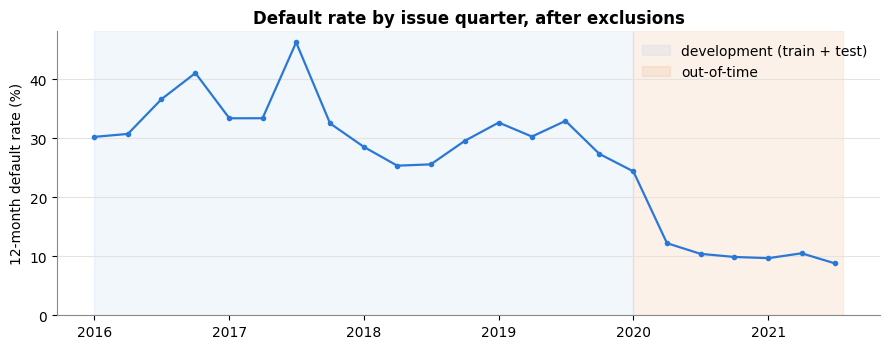

In [7]:
# Default rate by issue quarter, with the three windows shaded: the drift the model must survive.
q = (pop.assign(quarter=pop["issue_date"].dt.to_period("Q").dt.to_timestamp())
        .groupby("quarter")["y"].agg(["size", "mean"]))
fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp(DEV_START), pd.Timestamp(OOT_START), color=BLUE, alpha=0.06, label="development (train + test)")
ax.axvspan(pd.Timestamp(OOT_START), pd.Timestamp(OOT_END), color=ORANGE, alpha=0.10, label="out-of-time")
ax.plot(q.index, q["mean"] * 100, color=BLUE, marker="o", markersize=3, linewidth=1.6)
ax.set_ylabel("12-month default rate (%)")
ax.set_ylim(0, None)
ax.set_title("Default rate by issue quarter, after exclusions")
ax.legend(loc="upper right", frameon=False)
plt.tight_layout(); plt.show()

### What the result shows
* **Train 75,302 loans, test 32,273, OOT 48,150.** Train and test both have a default rate of 31.37%, which is what the stratified split guarantees.
* **The OOT default rate is less than half the development rate** (14.4% against 31.4%). The chart shows a sharp break in the second quarter of 2020: around 24% in Q1 2020, then about 10% to 12% for every quarter after. That quarter is when COVID hit, Bondora tightened approvals and Spanish lending stopped, so the break is part policy and part country mix.
* **Spain almost disappears from the OOT sample.** Bondora stopped new Spanish lending in March 2020, so Spain has only about 3,000 OOT loans, all issued in January to March 2020, against about 19,000 in development. Spain's default rate stays very high (above 50%) in both windows.
* Estonia dominates every sample, and Finland's default rate falls the most between development and OOT (from about 42% to 14%).

### Recommended action
* Use these three samples, unchanged, for every model in Phase 3 (WoE scorecard, LightGBM challenger, Bondora benchmark), so all three are compared on exactly the same loans.
* Because the OOT default rate is about half the development rate, expect the model's PDs to be too high on OOT even if its ranking is good. Judge OOT on **ranking** (Gini, KS) first, and treat calibration as a separate step (roadmap D10: recalibration).
* Spain's OOT check covers only one quarter of lending, just before COVID. Report Spain's OOT results with their confidence interval and say that they cover only Q1 2020; do not present them as a full out-of-time test for Spain.
* Because the country mix changes between samples, report Gini per country as well as pooled: a pooled Gini can rise or fall just because the mix changed.

## Step 4. Feature matrix through the registry

### Why this step
The registry and its test (Phase 2) guarantee that a leak *can* be caught. This step makes sure it *is* caught on the real data: the feature matrix X is built from `candidate_features`, and `check_model_columns` is called on it before anything else touches it. Every later notebook builds X the same way.

We also show the guard working: we try to add two forbidden columns, a leak (`PrincipalBalance`, the 2021 balance) and an excluded application field (`Interest`, D-012), and check that the guard refuses them with a clear reason.

Finally, a check of D-009 on the samples: every candidate should be filled in for most loans in **both** development and OOT. Bureau scores are judged within their own country, so for them we read all four scores straight from the warehouse (as a diagnostic, outside X). This check is what led to D-014.

In [8]:
# Load the candidate features for the sample loans only (the Kaggle columns keep their original names).
cols = ", ".join(f'"{c}"' for c in FEATURES)
con.register("sample_keys", pop[["loan_key"]])     # make the pandas key list visible to SQL
feats = sql(f"SELECT l.loan_key, {cols} FROM loans l JOIN sample_keys s USING (loan_key)").set_index("loan_key")

X = feats.loc[pop["loan_key"], FEATURES]            # same row order as pop; keys are the index, not a column
y = pop.set_index("loan_key")["y"]                  # the target lives outside X
sample = pop.set_index("loan_key")["sample"]

check_model_columns(X.columns, reg)                 # the leakage guard: raises LeakageError if anything is wrong
print(f"X: {X.shape[0]:,} loans x {X.shape[1]} features -- passed check_model_columns")
assert X.index.equals(y.index) and X.index.is_unique

X: 155,725 loans x 31 features -- passed check_model_columns


In [9]:
# Show the guard refusing forbidden columns.
for extra in (["PrincipalBalance"], ["Interest"]):
    try:
        check_model_columns([*X.columns, *extra], reg)
        print(f"{extra}: accepted  <-- this would be a bug")
    except LeakageError as err:
        print(f"{extra}: refused -> {err}")

['PrincipalBalance']: refused -> Not allowed in a model matrix: PrincipalBalance (leak)
['Interest']: refused -> Not allowed in a model matrix: Interest (application: D-012: Bondora's price carries Bondora's risk rating)


In [10]:
def missing_share(s: pd.Series) -> float:
    """Share of loans where the value is empty, or Bondora's code -1 for 'not collected'."""
    m = s.isna()
    if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
        m |= s.eq(-1)
    return m.mean()


is_dev = sample.isin(["train", "test"])
avail = pd.DataFrame({
    "missing_dev": X[is_dev].apply(missing_share),
    "missing_oot": X[~is_dev].apply(missing_share),
})
avail["note"] = [reg.columns[c].note for c in avail.index]
# Bureau scores are judged within their own country (D-009), so the pooled rate is shown but not judged.
bureau = avail.index.str.startswith("CreditScore")
avail["flag"] = ""
avail.loc[~bureau & ((avail["missing_dev"] > 0.5) | (avail["missing_oot"] > 0.5)), "flag"] = "check"
avail[["missing_dev", "missing_oot"]] = (avail[["missing_dev", "missing_oot"]] * 100).round(1)
avail.rename(columns={"missing_dev": "missing_dev_pct", "missing_oot": "missing_oot_pct"}).sort_values(
    "missing_oot_pct", ascending=False)

,missing_dev_pct,missing_oot_pct,note,flag
CreditScoreFiAsiakasTietoRiskGrade,75.1,78.7,"D-009: Finnish bureau, judge within country",
CreditScoreEeMini,42.7,27.5,"D-009: Estonian bureau, judge within country",
Education,0.0,1.5,,
EmploymentDurationCurrentEmployer,0.0,1.5,,
AppliedAmount,0.0,0.0,,
Country,0.0,0.0,"D-008: Slovakia kept in the pool, country is a...",
NewCreditCustomer,0.0,0.0,,
LoanDuration,0.0,0.0,,
Amount,0.0,0.0,,
HomeOwnershipType,0.0,0.0,,


In [11]:
# D-009: bureau scores are judged within their own country. Read all four from the warehouse
# (a diagnostic table, never a model input), then show the missing share (%) per country and window.
bureau_cols = [c for c in reg.columns if c.startswith("CreditScore")]
bcols = ", ".join(f'"{c}"' for c in bureau_cols)
bureau = sql(f"SELECT loan_key, {bcols} FROM loans JOIN sample_keys USING (loan_key)")
bureau = bureau.set_index("loan_key").loc[pop["loan_key"]]
win = sample.map({"train": "dev", "test": "dev", "oot": "oot"})
country = pop.set_index("loan_key")["country_name"]
(bureau[bureau_cols].apply(lambda s: s.isna() | s.astype(str).isin(["-1", ""]))
   .groupby([country, win]).mean().mul(100).round(1))

CreditScoreEsMicroL  CreditScoreEsEquifaxRisk  CreditScoreFiAsiakasTietoRiskGrade  CreditScoreEeMini
country_name sample                                                                                                      
Estonia      dev                    16.4                     100.0                               100.0                0.0
             oot                     0.0                     100.0                               100.0                0.0
Finland      dev                     9.2                     100.0                                 0.2              100.0
             oot                     7.0                     100.0                                 0.0              100.0
Spain        dev                     0.0                      57.0                               100.0              100.0
             oot                     0.0                     100.0                               100.0              100.0

In [12]:
# What value does the "Spanish" MicroL score hold for Estonian and Finnish loans?
pd.crosstab(country, bureau["CreditScoreEsMicroL"].fillna("missing"))

CreditScoreEsMicroL,M,M1,M10,M2,M3,M4,M5,M6,M7,M8,M9,missing
country_name,,,,,,,,,,,,
Estonia,86470,0,0,0,0,0,0,0,0,0,0,10109
Finland,33945,0,0,0,0,0,0,0,0,0,0,3183
Spain,13553,3501,3,1241,1133,1187,1102,247,8,33,10,0


### What the result shows
* X has one row per sample loan (155,725) and one column per candidate feature, and it passes `check_model_columns`. Keys are the row index and the target is a separate series, so neither can slip into the model as a feature.
* The guard refuses both test columns and says why: `PrincipalBalance` is a leak, `Interest` is excluded by D-012. This is the message a future reader would get if a feature were added by mistake.
* No non-bureau candidate is more than half missing in either window (the `flag` column is empty), so D-009 holds on the actual samples for the ordinary application fields.
* **The bureau scores, judged within their own country (as D-009 asks), show that both Spanish scores fail:**
  * `CreditScoreEeMini` (Estonia) and `CreditScoreFiAsiakasTietoRiskGrade` (Finland) are filled in for practically every loan of their own country in both windows. They pass D-009.
  * **`CreditScoreEsEquifaxRisk` fails D-009.** It is missing for 57% of Spanish development loans and for **every** Spanish OOT loan. The model could not use it on the OOT sample, and its "missing" bin would partly stand for "issued in 2020".
  * **`CreditScoreEsMicroL` fails D-009 too, in a hidden way.** It never looks missing, but the second table shows that most loans carry the plain code `M`, which is not a grade: every Estonian and Finnish loan, about 55% of Spanish development loans and **all 2,996 Spanish OOT loans**. A real grade (`M1` to `M10`) exists only for Spanish development loans. So on the OOT sample this score holds no information for any country, and in development `M` versus a grade would partly stand for "issued earlier".

### Recommended action
* In Phase 3, build X only with this pattern: `X = df[candidate_features(reg)]` (plus registered derived features), then `check_model_columns(X.columns, reg)` before every fit and every scoring call.
* **D-014:** both Spanish bureau scores (`CreditScoreEsEquifaxRisk`, `CreditScoreEsMicroL`) are no longer candidates in `config/feature_registry.yaml`, so they are already absent from X above. Spain stays represented through `Country` and the ordinary application fields.
* Keep the Estonian and Finnish scores. During binning, each is a normal feature within its own country; for the other countries its missing value only repeats what `Country` says, so it gets one shared bin.

## Step 5. Save the sample assignment

### Why this step
Phase 3 runs in other notebooks and scripts. They must use exactly these loans, in exactly these samples. Saving the assignment once (loan key, issue date, country, sample, target) means no later step re-draws the random split or re-applies the exclusions differently. The features are not saved: they are always re-read from the warehouse through the registry.

In [13]:
out = pop[["loan_key", "issue_date", "country_name", "sample", "y"]].reset_index(drop=True)
OUT.parent.mkdir(parents=True, exist_ok=True)
out.to_parquet(OUT, index=False)

check = pd.read_parquet(OUT)                       # read it back and confirm it is what we meant to write
assert len(check) == len(out) and check["loan_key"].is_unique
print(f"Wrote {OUT.relative_to(ROOT)}: {len(check):,} loans")
print(check["sample"].value_counts().reindex(order).to_string())

Wrote data\processed\model_samples.parquet: 155,725 loans
sample
train    75302
test     32273
oot      48150


### What the result shows
The file holds 155,725 unique loans: the train, test and OOT samples from step 3.

### Recommended action
* Phase 3 reads `data/processed/model_samples.parquet` instead of re-splitting.
* Later, move the waterfall and the split from this notebook into `src/pdengine/samples.py` with a test (counts per step, no overlap between samples, seed gives the same split), so `make train` can rebuild the samples without the notebook.

## Step 6. Summary of findings and recommended actions

### Findings

| # | Area | Finding | Recommended action | Decision |
|---|---|---|---|---|
| 1 | Returned loans | No Returned or InPostFundingReview loans are in the Kaggle join; all 4,252 are official-only. | Keep the filter as a guard. | D-010 |
| 2 | 14-day withdrawals | 2,894 loans were repaid within 14 days, with a 0% default rate: cancelled loans, not goods. | Removed from every sample. | roadmap |
| 3 | Slovakia | All 296 Slovak loans were issued in 2014 to January 2015, so the pre-2016 cut removes them; D-008 has no effect on Track A. | Recorded; D-008 unchanged. | D-008, D-013 |
| 4 | Pre-2016 | 20,616 loans from 2009 to 2015 removed (earlier product era). | Removed. | roadmap D3 |
| 5 | Missing target | None among loans issued up to July 2021. | Keep as a guard. | |
| 6 | Population | 155,725 loans remain, 40,671 bads (about 26%). | Use for all Track A models. | |
| 7 | Samples | Train 75,302, test 32,273 (stratified by year and target, seed 42), OOT 48,150. | Same samples for champion, challenger and benchmark. | |
| 8 | Default-rate drift | OOT default rate 14.4% against 31.4% in development, with a sharp break in Q2 2020. | Judge OOT on ranking first; recalibrate separately. | roadmap D10 |
| 9 | Spain | Spanish lending stops in March 2020: only about 3,000 OOT loans, all from Q1 2020. | Report Spain's OOT results with intervals and this caveat. | |
| 10 | Leakage guard | X built from the registry passes `check_model_columns`; leaks and D-012 columns are refused with reasons. | Use the same X-building pattern in every model step. | D-012 |
| 11 | Bureau scores | Estonian and Finnish scores pass D-009 within country. Both Spanish scores fail it: Equifax is missing for 57% of Spanish development loans and all Spanish OOT loans; MicroL carries only the non-grade code `M` on every OOT loan. | Both Spanish scores removed from the candidates; one shared bin for "other country" values. | D-009, D-014 |

### What this means for the next phase

Phase 3 can start: the samples are fixed in `data/processed/model_samples.parquet`, and the feature matrix is guarded. Next is binning the candidate features on the train sample (WoE and IV with `optbinning`), then the WoE logistic scorecard.

### The samples in one paragraph (for my video)

Before training anything, I decided which loans the model may learn from. I started with all 179,235 loans and removed them in a fixed order, showing what each rule does. Nearly 2,900 loans were cancelled within the 14-day withdrawal period, so they could never default; leaving them in would have made the book look safer. Loans from before 2016 belong to an earlier product era, and that cut also removes every Slovak loan. That leaves about 156,000 loans. I train on 2016 to 2019 and keep 2020 to mid-2021 completely aside as an out-of-time test, which is how a model is really used: built on the past, applied to the future. That test is hard on purpose. Default rates halved in 2020, and Spain stopped lending in March 2020, so the model has to prove it still ranks borrowers well when the world changes. Finally, every feature passes through a leakage guard that refuses anything the lender would not have known on the application day.

In [14]:
con.close()   # release the warehouse file